<a href="https://colab.research.google.com/github/guharoysuvhadip-ux/Second_hand_car_Project/blob/main/second_hand_car_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving car_sales_data.csv to car_sales_data.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

print("Libraries Loading")

Libraries Loading


In [ ]:
file_mane = list(uploaded.keys())[0]
df = pd.read_csv(file_name)
print("file loaded:", file_name)
df.head(10)

file loaded: car_sales_data.csv


,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price
0,Ford,Fiesta,1.0,Petrol,2002,127300,3074
1,Porsche,718 Cayman,4.0,Petrol,2016,57850,49704
2,Ford,Mondeo,1.6,Diesel,2014,39190,24072
3,Toyota,RAV4,1.8,Hybrid,1988,210814,1705
4,VW,Polo,1.0,Petrol,2006,127869,4101
5,Ford,Focus,1.4,Petrol,2018,33603,29204
6,Ford,Mondeo,1.8,Diesel,2010,86686,14350
7,Toyota,Prius,1.4,Hybrid,2015,30663,30297
8,VW,Polo,1.2,Petrol,2012,73470,9977
9,Ford,Focus,2.0,Diesel,1992,262514,1049


In [ ]:
df.describe()

,Engine size,Year of manufacture,Mileage,Price
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.773058,2004.209440,112497.320700,13828.903160
std,0.734108,9.645965,71632.515602,16416.681336
min,1.000000,1984.000000,630.000000,76.000000
25%,1.400000,1996.000000,54352.250000,3060.750000
50%,1.600000,2004.000000,100987.500000,7971.500000
75%,2.000000,2012.000000,158601.000000,19026.500000
max,5.000000,2022.000000,453537.000000,168081.000000


In [ ]:
print("Rows and columns:", df.shape)

print()

df.info()

Rows and columns: (50000, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Manufacturer         50000 non-null  object 
 1   Model                50000 non-null  object 
 2   Engine size          50000 non-null  float64
 3   Fuel type            50000 non-null  object 
 4   Year of manufacture  50000 non-null  int64  
 5   Mileage              50000 non-null  int64  
 6   Price                50000 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 2.7+ MB


In [ ]:
print(df.isnull().sum())
print()

print("Total Missing Value:",df.isnull().sum().sum())

Manufacturer           0
Model                  0
Engine size            0
Fuel type              0
Year of manufacture    0
Mileage                0
Price                  0
dtype: int64

Total Missing Value: 0


In [ ]:

import pandas as pd

# Load dataset
df = pd.read_csv('car_sales_data.csv')

# Convert Year of manufacture to integer
df['Year of manufacture'] = df['Year of manufacture'].astype(int)
# Convert Mileage to integer
df['Mileage'] = df['Mileage'].astype(int)

# Create a new Age column
df['Car Age'] = 2026 - df['Year of manufacture']

# Check dataset
print(df.head())
# Check data types
print(df.dtypes)



  Manufacturer       Model  Engine size Fuel type  Year of manufacture  \
0         Ford      Fiesta          1.0    Petrol                 2002   
1      Porsche  718 Cayman          4.0    Petrol                 2016   
2         Ford      Mondeo          1.6    Diesel                 2014   
3       Toyota        RAV4          1.8    Hybrid                 1988   
4           VW        Polo          1.0    Petrol                 2006   

   Mileage  Price  Car Age  
0   127300   3074       24  
1    57850  49704       10  
2    39190  24072       12  
3   210814   1705       38  
4   127869   4101       20  
Manufacturer            object
Model                   object
Engine size            float64
Fuel type               object
Year of manufacture      int64
Mileage                  int64
Price                    int64
Car Age                  int64
dtype: object


In [ ]:
print("Duplicate rows before :", df.duplicated().sum())
df = df.drop_duplicates()
df = df.reset_index(drop = True)
print("Duplicate rows after :", df.duplicated().sum())
print("new shape :",df.shape)

Duplicate rows before : 12
Duplicate rows after : 0
new shape : (49988, 8)


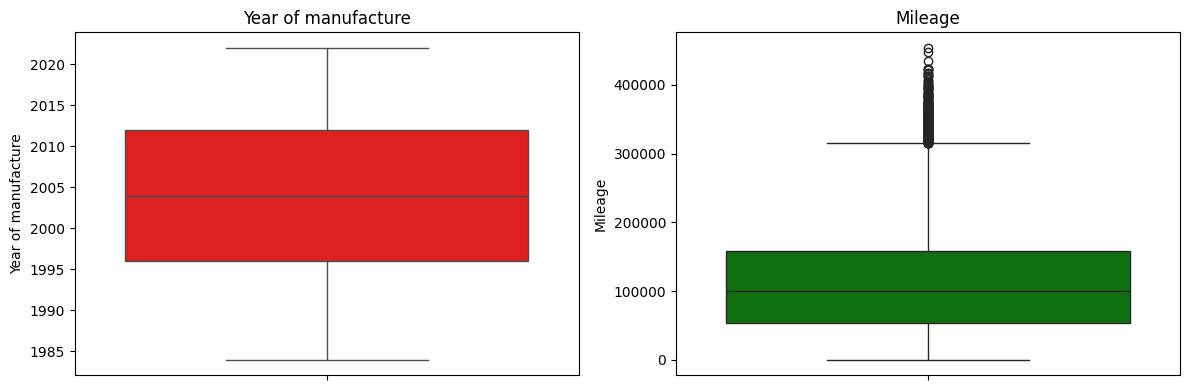

In [ ]:
import pandas as pd

df = pd.read_csv('/content/car_sales_data.csv')

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
sns.boxplot(data=df, y='Year of manufacture', color='red')
plt.title('Year of manufacture')

plt.subplot(1,2,2)
sns.boxplot(y=df['Mileage'], color='green')
plt.title('Mileage')

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

df = pd.read_csv('/content/car_sales_data.csv')
def remove_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return data[(data[column] >= lower) & (data[column] <= upper)]


before = len(df)

df = remove_outliers(df, 'Mileage')
df = remove_outliers(df, 'Engine size')

df = df.reset_index(drop=True)

print("Rows before:", before)
print("Rows after :", len(df))
print("Rows removed:", before - len(df))

Rows before: 50000
Rows after : 45700
Rows removed: 4300


In [ ]:
print("clearn data shape:", df.shape)
print("Missing value:", df.duplicated().sum().sum())
print("Duplicates:",df.duplicated())
df.head()

clearn data shape: (45700, 7)
Missing value: 12
Duplicates: 0        False
1        False
2        False
3        False
4        False
         ...  
45695    False
45696    False
45697    False
45698    False
45699    False
Length: 45700, dtype: bool


,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price
0,Ford,Fiesta,1.0,Petrol,2002,127300,3074
1,Ford,Mondeo,1.6,Diesel,2014,39190,24072
2,Toyota,RAV4,1.8,Hybrid,1988,210814,1705
3,VW,Polo,1.0,Petrol,2006,127869,4101
4,Ford,Focus,1.4,Petrol,2018,33603,29204


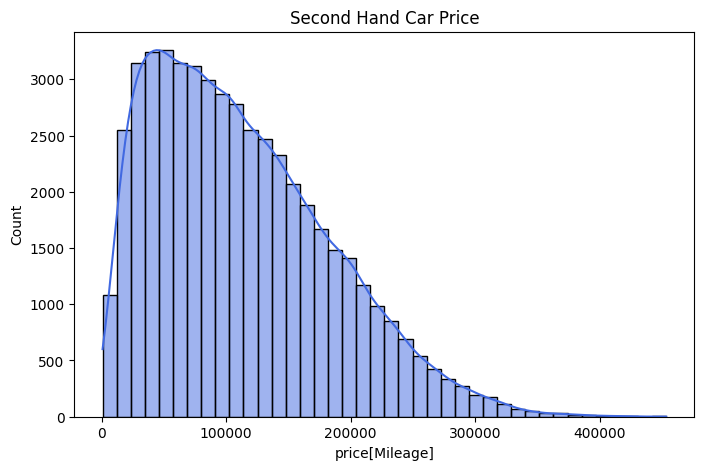

In [ ]:
import pandas as pd
df = pd.read_csv('/content/car_sales_data.csv')
plt.figure(figsize=(8, 5))

sns.histplot(df['Mileage'], bins=40, kde=True, color='royalblue')
plt.title("Second Hand Car Price")
plt.xlabel("price[Mileage]")
plt.show()

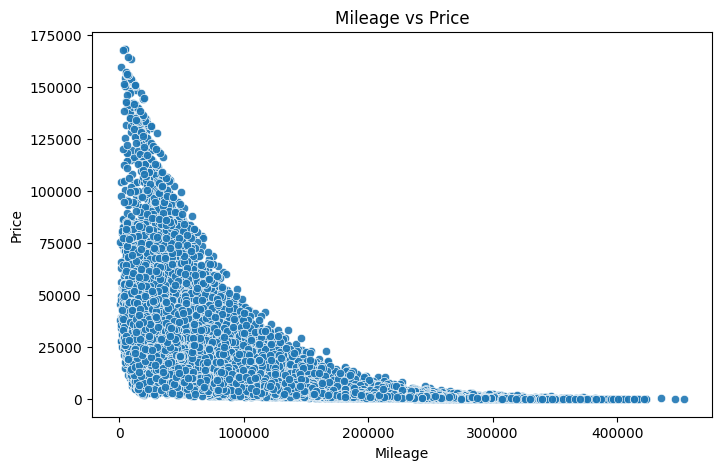

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='Mileage',
    y='price',
    data=df,
    alpha=0.9
)

plt.title('Mileage vs Price')
plt.xlabel('Mileage')
plt.ylabel('Price')

plt.show()



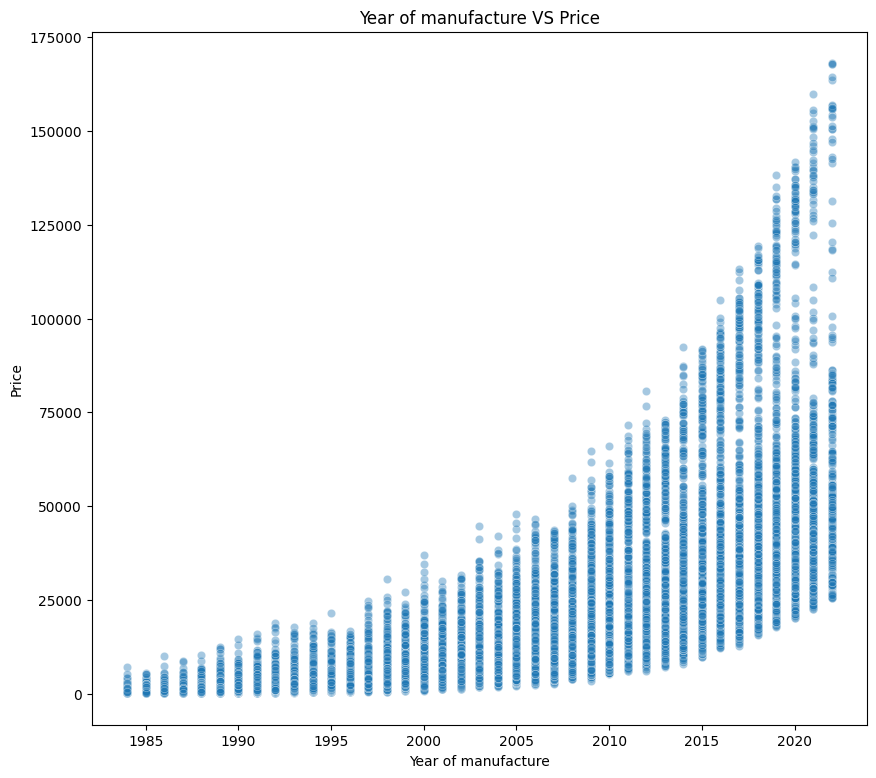

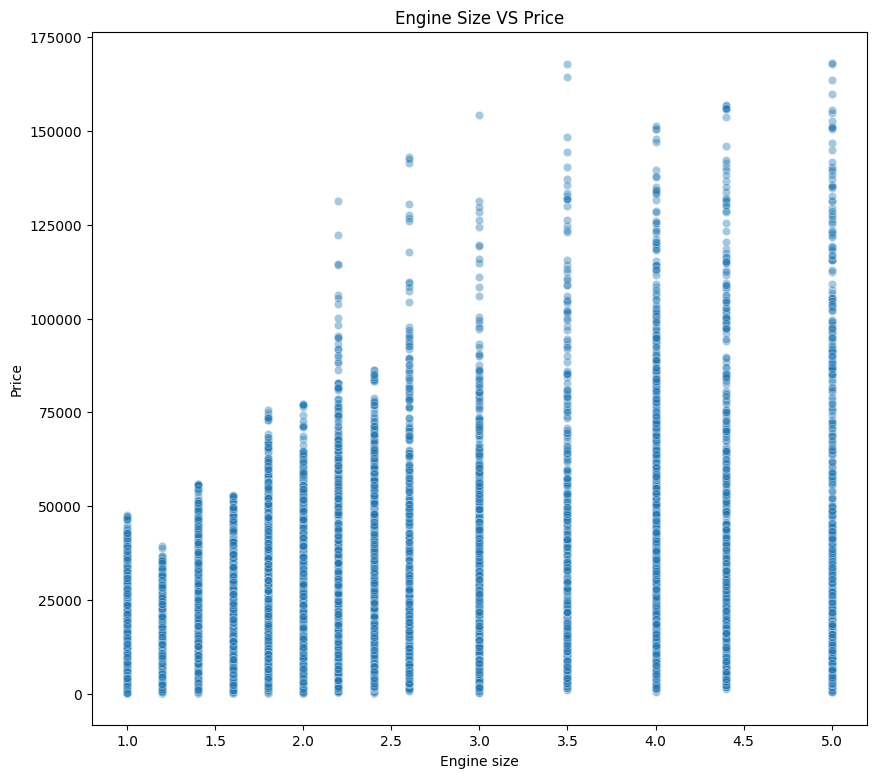

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.read_csv('/content/car_sales_data.csv')

plt.figure(figsize=(10,9))

sns.scatterplot(x='Year of manufacture', y='Price', data=df, alpha=0.4)
plt.title('Year of manufacture VS Price')
plt.xlabel('Year of manufacture')
plt.ylabel('Price')
plt.show()


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/car_sales_data.csv')

plt.figure(figsize=(10,9))

sns.scatterplot(x='Engine size', y='Price', data=df, alpha=0.4)

plt.title('Engine Size VS Price')
plt.xlabel('Engine size')
plt.ylabel('Price')

plt.show()


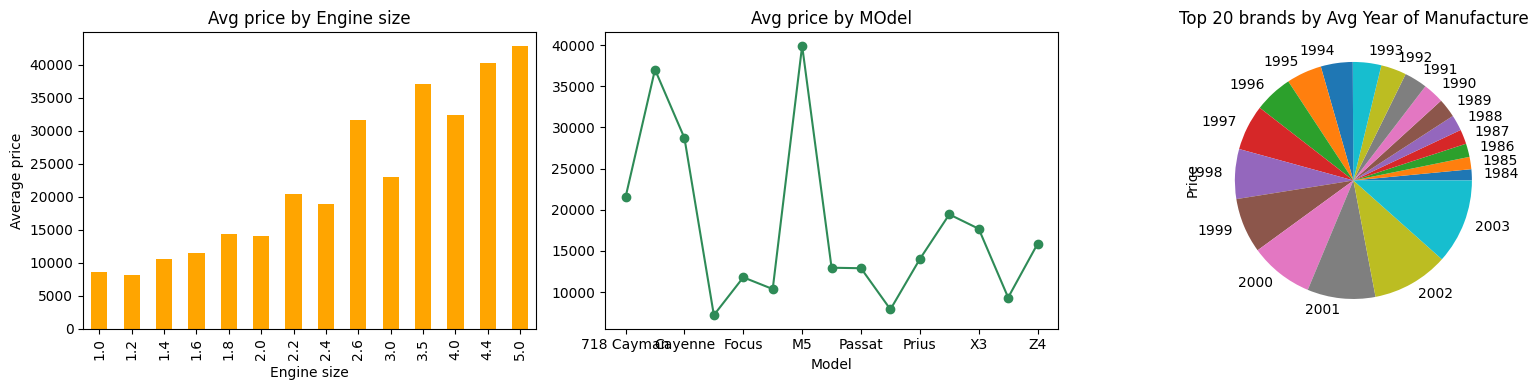

In [ ]:
# Average price by cylinders, year and brand
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
df.groupby('Engine size')['Price'].mean().plot(kind='bar', color='orange')
plt.title('Avg price by Engine size')
plt.ylabel('Average price')

plt.subplot(1, 3, 2)
df.groupby('Model')['Price'].mean().plot(kind='line', color='seagreen', marker='o')
plt.title('Avg price by MOdel')

plt.subplot(1, 3, 3)
df.groupby('Year of manufacture')['Price'].mean().head(20).plot(kind='pie', color='tomato')
plt.title('Top 20 brands by Avg Year of Manufacture')

plt.tight_layout()
plt.show()

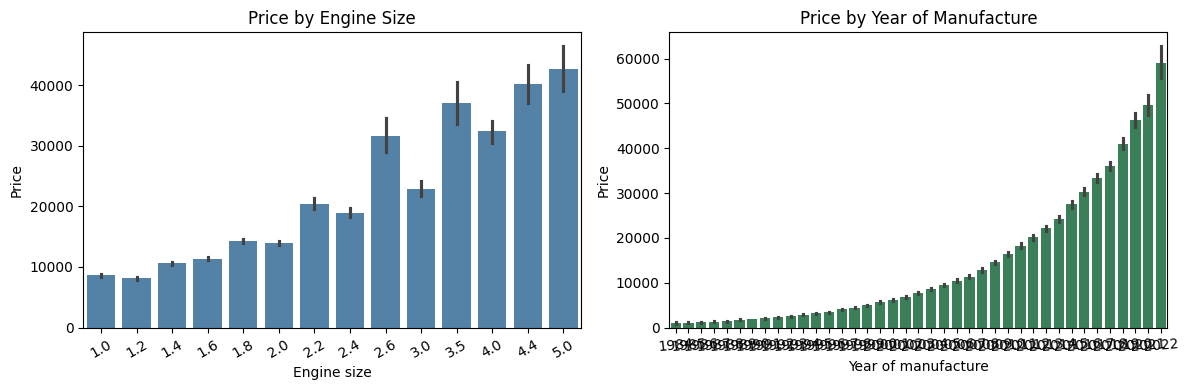

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.barplot(x='Engine size', y='Price', data=df, color='steelblue')
plt.title('Price by Engine Size')
plt.xticks(rotation=30)

plt.subplot(1, 2, 2)
sns.barplot(x='Year of manufacture', y='Price', data=df, color='seagreen')
plt.title('Price by Year of Manufacture')
plt.xticks(rotation=5)

plt.tight_layout()
plt.show()


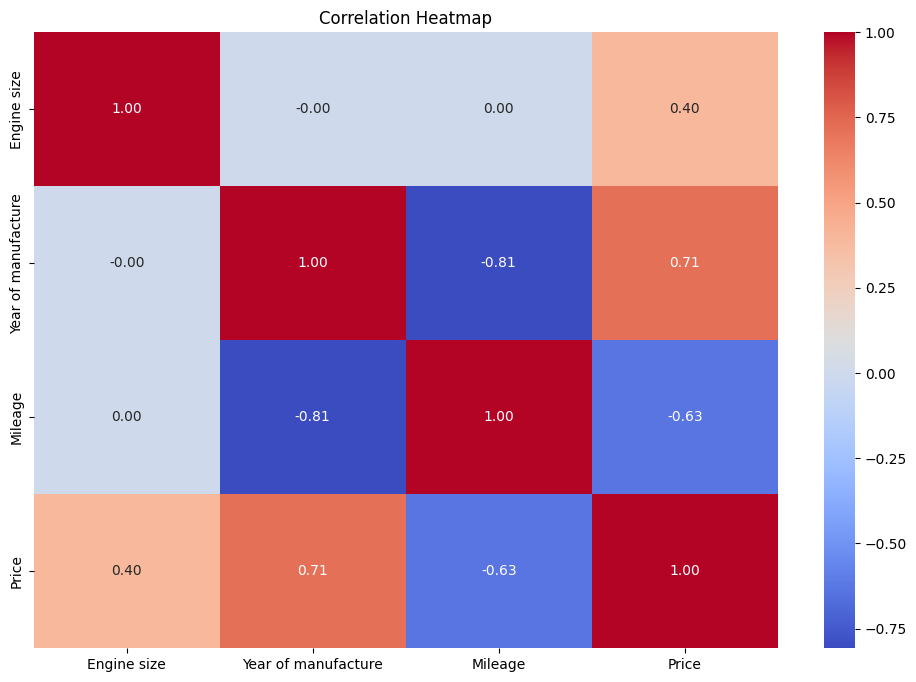

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
X = df[
    [
       'Manufacturer',
       'Model',
       'Engine size',
       'Fuel type',
       'Year of manufacture',
       'Mileage'
    ]
]

y = df['Price']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (50000, 6)
y shape: (50000,)


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

Training rows: 40000
Testing rows : 10000


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_cols = ['Manufacturer', 'Model', 'Fuel type']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [ ]:

from sklearn.metrics import r2_score, mean_absolute_error

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"R² Score: {r2:.2f}")
print(f"Average error (MAE): {mae:,.0f}")

R² Score: 0.68
Average error (MAE): 5,978


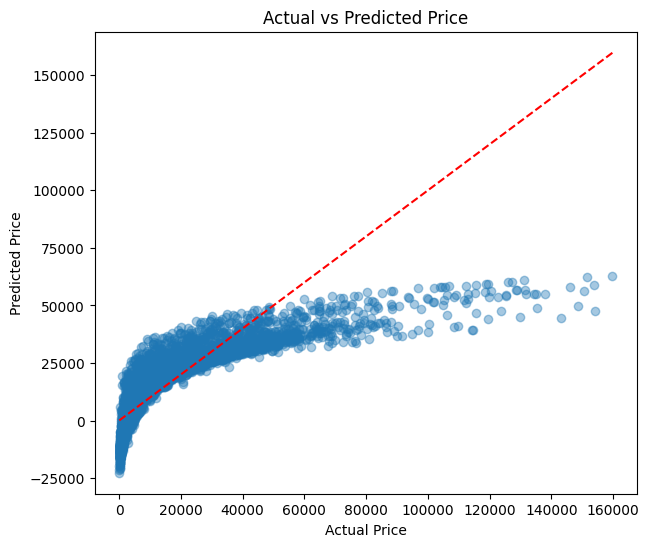

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Price')
plt.show()

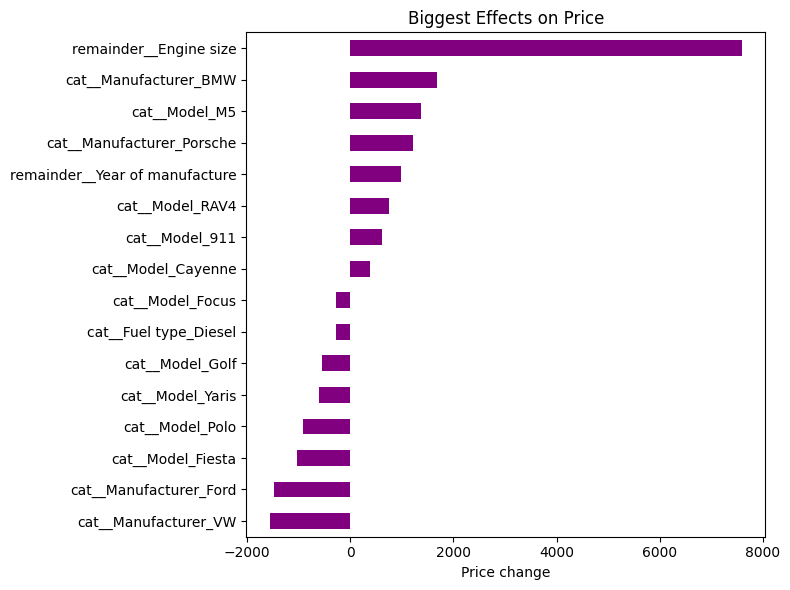

In [ ]:
regressor = model.named_steps['regressor']

feature_names = model.named_steps['preprocessor'].get_feature_names_out()

coef = pd.Series(regressor.coef_,index=feature_names).sort_values()

top = pd.concat([coef.head(8), coef.tail(8)])

plt.figure(figsize=(8, 6))
top.plot(kind='barh', color='purple')
plt.title('Biggest Effects on Price')
plt.xlabel('Price change')
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
df = pd.read_csv('/content/car_sales_data.csv')
new_car = pd.DataFrame({
    'Manufacturer': ['Toyota'],
    'Model': ['RAV4'],
    'Engine size': [1.8],
    'Fuel type': ['Hybrid'],
    'Year of manufacture': [2018],
    'Mileage': [50000]
})

In [ ]:
predicted_price = model.predict(new_car)[0]
print(f" Predicted price: ${predicted_price:,.0f}")

 Predicted price: $32,160
